# Diemer19 vs. fitted power-law $\alpha_{\rm cm}$ — with the real-data result overlaid

Recreates the comparison figure from `reports/2026-07-26_boost_factors_variance_floor_alpha_cm.tex`
(§6, "The mass-concentration slope in context", `fig:diemer`) — the source
script for that figure was never checked into the repo, so this rebuilds
it from the report's method description and the real-data checkpoints,
then adds a new element the original figure didn't have: a line (with a
68% credible band) showing the mass-concentration slope $\alpha_{\rm cm}$
the joint fit actually recovered from the real WaZP+DES-Y3 data, so it can
be compared directly against the two Diemer & Joyce (2019)-derived
power-law slopes.

**Method** (see the report for the full derivation):
1. Load the combined (bootstrap-pooled) posterior of the converged 6-bin
   real-data joint fit (`run_2026-07-25T21-21-08`,
   `wazp_desy3_inference_boost_floor6.yaml` — boost- and
   covariance-floor-corrected, $\alpha_{\rm cm}=+0.076\,^{+0.075}_{-0.071}$).
2. Evaluate the Diemer & Joyce (2019) $c_{200m}(M,z)$ relation at fixed
   $z=z_{\rm ref}=0.35$ over the WaZP sample's mass range (mass from the
   fit's own converged mass-richness slopes, at fixed $z$ to avoid the
   $z$-$M$ correlation contamination described in the report).
3. Fit a power law to $\log_{10}c$ vs.\ $\log_{10}M$ two ways: unweighted
   over a log-uniform richness grid, and weighted by each real cluster's
   Fisher information on $\alpha_{\rm cm}$ (its actual statistical
   contribution to constraining the parameter, using its boost- and
   floor-corrected covariance and a numerical derivative of the forward
   model).
4. **New:** overlay the real-data fit's own $\alpha_{\rm cm}$ posterior as
   a third line, anchored at the Diemer19 curve's value at the middle of
   the sample's mass range (not the model's $\log_{10}M_{\rm piv}=14.0$
   normalisation pivot, which sits nearly a full dex below the sample and
   would make the comparison mostly about amplitude extrapolation rather
   than a legible local slope comparison), with a shaded 68% credible
   band built from the pooled posterior's own $\alpha_{\rm cm}$ samples.


In [1]:
import os
import json
import pickle

import numpy as np
import yaml
import matplotlib.pyplot as plt
from astropy.table import Table
from cluster_toolkit.boostfactors import boost_powerlaw_at_R

from destacking.model import (
    diemer19_c200m, forward_model_combined, _MC_M_PIVOT_LOG, _MC_Z_REF,
)
from destacking.relations import mass_lambda_McClintock18


Lookup tables loaded!


## 1. Real-data fit results — load and pool the combined posterior

Same run and pooling convention as
`wazp_desy3_boost_floor6_combined_corner.ipynb`: each bootstrap's weights
renormalised to sum to 1 first (equal mass per bootstrap), then
concatenated and renormalised again.


In [2]:
# nautilus output chains live outside the repo (moved 2026-07-27, see
# project memory real-data-relocated).
RUN_DIR = os.path.expanduser("~/destacking_data/output/run_2026-07-25T21-21-08")
SIM_SUBDIR = os.path.join(RUN_DIR, "simulation_g00_gamma+0.0")

REAL_DATA_DIR = os.path.expanduser(
    "~/destacking_data/real_data/wazp_real_data_floor6/simulation_g00_gamma+0.0"
)
FIT_CONFIG_PATH = "../scripts/wazp_desy3_inference_boost_floor6.yaml"


def weighted_quantile(v, w, q):
    v = np.asarray(v)
    w = np.asarray(w)
    sorter = np.argsort(v)
    cs = np.cumsum(w[sorter]) / w.sum()
    return float(np.interp(q, cs, v[sorter]))


In [3]:
bootstrap_dirs = sorted(
    d for d in os.listdir(SIM_SUBDIR) if d.startswith("bootstrap_")
)

pool_samples, pool_weights = [], []
param_order = None
n_converged, n_incomplete = 0, 0
for d in bootstrap_dirs:
    subdir = os.path.join(SIM_SUBDIR, d)
    summary_path = os.path.join(subdir, "summary.json")
    npz_path = os.path.join(subdir, "gamma_posterior.npz")
    if not (os.path.exists(summary_path) and os.path.exists(npz_path)):
        n_incomplete += 1
        continue
    with open(summary_path) as f:
        summary = json.load(f)
    if summary.get("converged", True) is False:
        continue
    n_converged += 1

    npz = np.load(npz_path, allow_pickle=True)
    this_order = [str(p) for p in npz["param_order"]]
    if param_order is None:
        param_order = this_order
    assert this_order == param_order, f"{d}: param_order mismatch"

    w = npz["weights"]
    pool_samples.append(npz["all_samples"])
    pool_weights.append(w / w.sum())

samples_all = np.concatenate(pool_samples)
weights_all = np.concatenate(pool_weights)
weights_all = weights_all / weights_all.sum()

print(f"bootstraps: {n_converged}/{len(bootstrap_dirs)} converged and pooled "
      f"({n_incomplete} incomplete)")
print(f"param_order: {param_order}")
print(f"pooled samples: {samples_all.shape}")


bootstraps: 50/50 converged and pooled (0 incomplete)
param_order: ['c0', 'alpha_cm', 'beta_cm', 'gamma_cm', 'log_M_norm', 'alpha_mr', 'beta_mr', 'f_mis', 'sigma_off']
pooled samples: (1355832, 9)


In [4]:
param_idx = {name: i for i, name in enumerate(param_order)}
med, lo, hi = {}, {}, {}
for name in param_order:
    col = samples_all[:, param_idx[name]]
    med[name] = weighted_quantile(col, weights_all, 0.50)
    lo[name]  = weighted_quantile(col, weights_all, 0.16)
    hi[name]  = weighted_quantile(col, weights_all, 0.84)

print(f"{'param':>12}  {'median':>8}  {'+68%':>7}  {'-68%':>7}")
for name in param_order:
    print(f"{name:>12}  {med[name]:8.4f}  {hi[name]-med[name]:+7.4f}  "
          f"{med[name]-lo[name]:-7.4f}")


       param    median     +68%     -68%
          c0    5.6253  +1.3990   1.2077
    alpha_cm    0.0756  +0.0749   0.0708
     beta_cm   -0.1926  +0.4790   0.4519
    gamma_cm    0.0272  +0.0337   0.0328
  log_M_norm   -0.1465  +0.0191   0.0200
    alpha_mr    1.0560  +0.0530   0.0467
     beta_mr   -0.3638  +0.0518   0.0499
       f_mis    0.2600  +0.1006   0.1282
   sigma_off    0.5081  +0.1365   0.1154


## 2. Real WaZP+DES-Y3 sample — richness, masses at fixed $z_{\rm ref}$, boost+floor covariances

Loads the same real-data checkpoint the fit itself used, applies the same
`r_min_fit` bin cut and per-stack boost correction as
`gamma_inference.py`'s `_apply_boost_correction` (the covariance floor is
already baked into this checkpoint's measurement — see project memory
bootstrap-covariance-floor-bug — so only the boost step needs
reproducing here).


In [5]:
co = np.load(os.path.join(REAL_DATA_DIR, "cluster_obs.npz"))
Lambda_real     = co["Lambda"]
delta_m_real    = co["delta_m"]
stack_name_real = co["stack_name"]
N = len(Lambda_real)
print(f"N clusters: {N:,}   Lambda range: [{Lambda_real.min():.1f}, "
      f"{Lambda_real.max():.1f}]")

raw = np.load(os.path.join(REAL_DATA_DIR, "simulated_data.npz"))
data_vectors = raw["data_vectors"]
cov_matrices = raw["cov_matrices"]

with open(FIT_CONFIG_PATH) as f:
    fit_cfg = yaml.safe_load(f)

FIT_RADII = np.logspace(
    fit_cfg["fit_log_inner_radius"], fit_cfg["fit_log_outer_radius"],
    fit_cfg["fit_n_radii"],
)
keep = FIT_RADII >= fit_cfg["r_min_fit"]
RADII_fit = FIT_RADII[keep]
dv_fit = data_vectors[:, keep].copy()
cv_fit = cov_matrices[:, keep][:, :, keep].copy()
print(f"RADII_fit [Mpc]: {np.round(RADII_fit, 3)}")


N clusters: 15,967   Lambda range: [25.0, 294.7]
RADII_fit [Mpc]: [0.251 0.437 0.759 1.318 2.291 3.981]


In [6]:
# Per-stack boost correction, exactly matching gamma_inference.py's
# _apply_boost_correction: multiply each cluster's data vector/covariance
# by its stack's fitted boost(R).
with open(fit_cfg["boosts"], "rb") as f:
    BOOST_FITS = pickle.load(f)["boost_fits"]

n_corrected = 0
boost_cache = {}
for i, name in enumerate(stack_name_real):
    if not name:
        continue
    fit = BOOST_FITS.get(name)
    if fit is None or fit.get("failed"):
        continue
    bvec = boost_cache.get(name)
    if bvec is None:
        bvec = boost_powerlaw_at_R(RADII_fit, fit["B0"], fit["Rs"], fit["alpha"])
        boost_cache[name] = bvec
    dv_fit[i] *= bvec
    cv_fit[i] *= np.outer(bvec, bvec)
    n_corrected += 1
print(f"boost-corrected: {n_corrected:,}/{N:,} clusters "
      f"({N - n_corrected:,} with no usable stack fit)")


boost-corrected: 15,771/15,967 clusters (196 with no usable stack fit)


In [7]:
# Mass at FIXED z_ref (not each cluster's own z) -- Eq. mr's beta_mr term
# vanishes exactly at z=z_ref, isolating the mass dependence the way
# alpha_cm is defined (see report Section 6.2 on z-M contamination).
logM_real = (
    mass_lambda_McClintock18(Lambda_real, _MC_Z_REF,
                             Flambda=med["alpha_mr"], Gz=med["beta_mr"])
    + med["log_M_norm"]
)
M_real = 10.0 ** logM_real
c_diemer_real = diemer19_c200m(M_real, np.full(N, _MC_Z_REF))
print(f"log10(M/Msun) range: [{logM_real.min():.3f}, {logM_real.max():.3f}]")


log10(M/Msun) range: [14.127, 15.258]


## 3. Diemer19 $c(M)$ and power-law fits (log-uniform grid, Fisher-weighted)


In [8]:
# Log-uniform richness grid spanning the real sample's range (matches the
# report's Lambda in [25, 295]).
Lambda_grid = np.logspace(np.log10(max(25.0, Lambda_real.min())),
                          np.log10(Lambda_real.max()), 200)
logM_grid = (
    mass_lambda_McClintock18(Lambda_grid, _MC_Z_REF,
                             Flambda=med["alpha_mr"], Gz=med["beta_mr"])
    + med["log_M_norm"]
)
M_grid = 10.0 ** logM_grid
c_diemer_grid = diemer19_c200m(M_grid, np.full(len(M_grid), _MC_Z_REF))


def fit_powerlaw(logM, logc, weights=None):
    """Weighted least squares: log10(c) = log10(c0) + alpha*(log10(M) - M_piv)."""
    if weights is None:
        weights = np.ones_like(logM)
    A = np.column_stack([np.ones_like(logM), logM - _MC_M_PIVOT_LOG])
    ATA = A.T @ (weights[:, None] * A)
    ATy = A.T @ (weights * logc)
    coeff = np.linalg.solve(ATA, ATy)
    return float(10 ** coeff[0]), float(coeff[1])


c0_grid, alpha_grid = fit_powerlaw(logM_grid, np.log10(c_diemer_grid))
c0_count, alpha_count = fit_powerlaw(logM_real, np.log10(c_diemer_real))
print(f"unweighted, log-uniform grid:        alpha_cm = {alpha_grid:+.4f}")
print(f"unweighted, real richness dist.:      alpha_cm = {alpha_count:+.4f}")


unweighted, log-uniform grid:        alpha_cm = -0.0016
unweighted, real richness dist.:      alpha_cm = -0.0408


In [9]:
# Fisher information per cluster on alpha_cm at the fitted parameters,
# z held fixed at z_ref (Eq. fisher): F_i = (d(DeltaSigma_i)/d(alpha_cm))^T
# C_i^-1 (d(DeltaSigma_i)/d(alpha_cm)), numerical derivative of the forward
# model, real per-cluster boost+floor covariance.
cluster_table_zref = Table({
    "z":       np.full(N, _MC_Z_REF),
    "Lambda":  Lambda_real,
    "delta_m": delta_m_real,
})
FMISS_const     = np.full(N, med["f_mis"])
SIGMA_OFF_const = np.full(N, med["sigma_off"])

d_alpha = 1e-3
common_kwargs = dict(
    beta_cm=med["beta_cm"], log_M_norm=med["log_M_norm"],
    alpha_mr=med["alpha_mr"], beta_mr=med["beta_mr"],
    FMISS=FMISS_const, SIGMA_OFF=SIGMA_OFF_const,
)
model_plus = forward_model_combined(
    med["c0"], med["alpha_cm"] + d_alpha, med["gamma_cm"],
    cluster_table_zref, RADII_fit, **common_kwargs,
)
model_minus = forward_model_combined(
    med["c0"], med["alpha_cm"] - d_alpha, med["gamma_cm"],
    cluster_table_zref, RADII_fit, **common_kwargs,
)
d_model_d_alpha = (model_plus - model_minus) / (2 * d_alpha)

F_i = np.zeros(N)
n_used = 0
for i in range(N):
    valid = np.isfinite(dv_fit[i]) & np.isfinite(d_model_d_alpha[i])
    if valid.sum() == 0:
        continue
    deriv = d_model_d_alpha[i][valid]
    cov = cv_fit[i][np.ix_(valid, valid)]
    try:
        x = np.linalg.solve(cov, deriv)
    except np.linalg.LinAlgError:
        continue
    F_i[i] = float(deriv @ x)
    n_used += 1

order = np.argsort(logM_real)
top_quintile = order[int(0.8 * N):]
print(f"Fisher info computed for {n_used:,}/{N:,} clusters")
print(f"top mass quintile (20% by count) carries "
      f"{100 * F_i[top_quintile].sum() / F_i.sum():.0f}% of total Fisher info")

c0_fisher, alpha_fisher = fit_powerlaw(
    logM_real, np.log10(c_diemer_real), weights=F_i,
)
print(f"Fisher-information-weighted:           alpha_cm = {alpha_fisher:+.4f}")


Fisher info computed for 15,925/15,967 clusters
top mass quintile (20% by count) carries 87% of total Fisher info
Fisher-information-weighted:           alpha_cm = +0.0047


## 4. NEW — the real-data joint fit's own $\alpha_{\rm cm}$, with a credible band

Anchored to the Diemer19 curve's value at the middle of the sample's mass
range, not the model's $\log_{10}M_{\rm piv}=14.0$ pivot (which sits
almost a full dex below the sample and would make the line mostly about
amplitude extrapolation rather than a legible local slope comparison).
The band is the pooled posterior's own $\alpha_{\rm cm}$ samples fanned
from that anchor — zero width at the anchor mass, widening away from it,
correctly asymmetric since the fit's $\alpha_{\rm cm}$ posterior is
itself asymmetric.


In [10]:
rng = np.random.default_rng(0)
n_draw = 4000
draw_idx = rng.choice(len(weights_all), size=n_draw,
                      p=weights_all / weights_all.sum())
alpha_samp = samples_all[draw_idx, param_idx["alpha_cm"]]

anchor_logM = float(np.median(logM_grid))
anchor_logc = float(np.log10(
    diemer19_c200m(np.array([10.0 ** anchor_logM]), np.array([_MC_Z_REF]))[0]
))

logM_line = np.linspace(logM_grid.min(), logM_grid.max(), 200)
logc_samples = anchor_logc + alpha_samp[:, None] * (logM_line[None, :] - anchor_logM)
real_med = np.median(logc_samples, axis=0)
real_lo  = np.percentile(logc_samples, 16, axis=0)
real_hi  = np.percentile(logc_samples, 84, axis=0)

print(f"anchor: log10(M/Msun)={anchor_logM:.3f}, log10(c)={anchor_logc:.3f} "
      f"(Diemer19 value there)")
print(f"real-data alpha_cm = {med['alpha_cm']:+.4f} "
      f"+{hi['alpha_cm']-med['alpha_cm']:.4f} "
      f"-{med['alpha_cm']-lo['alpha_cm']:.4f}  (68% CL)")


anchor: log10(M/Msun)=14.693, log10(c)=0.700 (Diemer19 value there)
real-data alpha_cm = +0.0756 +0.0749 -0.0708  (68% CL)


## 5. Figure

Two panels, matching the report's `fig:diemer`: *top* — Diemer19 $c(M)$
at $z=0.35$ (solid black) with the two literature-derived power-law fits
and the new real-data line+band; *bottom* — the real sample's mass
distribution by cluster count (grey bars) vs. by share of total
$\alpha_{\rm cm}$ Fisher information (red line).


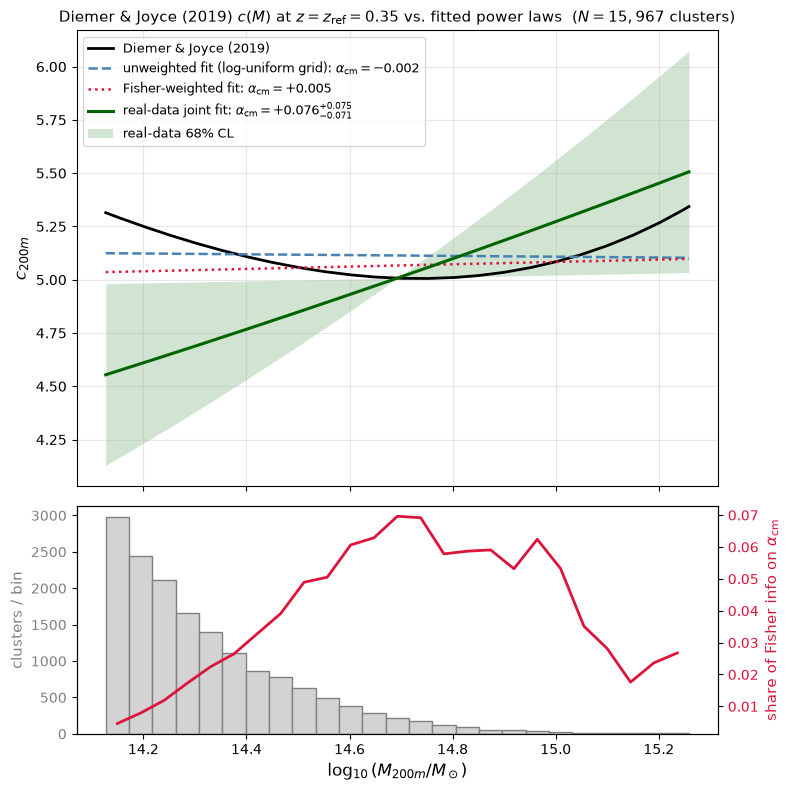

Saved figs/diemer19_alpha_cm_prediction_with_fit.png


In [11]:
logc_grid_fit   = np.log10(c0_grid)   + alpha_grid   * (logM_line - _MC_M_PIVOT_LOG)
logc_fisher_fit = np.log10(c0_fisher) + alpha_fisher * (logM_line - _MC_M_PIVOT_LOG)
c_diemer_line = diemer19_c200m(10.0 ** logM_line, np.full(len(logM_line), _MC_Z_REF))

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(8, 8), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

ax_top.plot(logM_line, c_diemer_line, color="black", lw=2.0,
            label="Diemer & Joyce (2019)")
ax_top.plot(logM_line, 10 ** logc_grid_fit, color="steelblue", lw=1.8, ls="--",
            label=rf"unweighted fit (log-uniform grid): $\alpha_{{\rm cm}}={alpha_grid:+.3f}$")
ax_top.plot(logM_line, 10 ** logc_fisher_fit, color="crimson", lw=1.8, ls=":",
            label=rf"Fisher-weighted fit: $\alpha_{{\rm cm}}={alpha_fisher:+.3f}$")
ax_top.plot(logM_line, 10 ** real_med, color="darkgreen", lw=2.2,
            label=(rf"real-data joint fit: $\alpha_{{\rm cm}}={med['alpha_cm']:+.3f}"
                   rf"^{{+{hi['alpha_cm']-med['alpha_cm']:.3f}}}"
                   rf"_{{-{med['alpha_cm']-lo['alpha_cm']:.3f}}}$"))
ax_top.fill_between(logM_line, 10 ** real_lo, 10 ** real_hi,
                    color="darkgreen", alpha=0.18, lw=0,
                    label="real-data 68% CL")
ax_top.set_ylabel(r"$c_{200m}$", fontsize=12)
ax_top.set_title(
    rf"Diemer & Joyce (2019) $c(M)$ at $z=z_{{\rm ref}}=0.35$ vs. fitted "
    rf"power laws  ($N={N:,}$ clusters)",
    fontsize=11,
)
ax_top.legend(fontsize=9, loc="best")
ax_top.grid(alpha=0.3)

bins = np.linspace(logM_real.min(), logM_real.max(), 26)
counts, edges = np.histogram(logM_real, bins=bins)
fisher_sum, _ = np.histogram(logM_real, bins=bins, weights=F_i)
centers = 0.5 * (edges[1:] + edges[:-1])

ax_bot.bar(centers, counts, width=np.diff(edges), color="lightgrey",
           edgecolor="grey", label="sample count")
ax_bot.set_ylabel("clusters / bin", color="grey", fontsize=11)
ax_bot.set_xlabel(r"$\log_{10}(M_{200m}/M_\odot)$", fontsize=12)
ax_bot.tick_params(axis="y", labelcolor="grey")

ax_bot2 = ax_bot.twinx()
ax_bot2.plot(centers, fisher_sum / fisher_sum.sum(), color="crimson", lw=2.0,
             label=r"share of total $\alpha_{\rm cm}$ Fisher info")
ax_bot2.set_ylabel(r"share of Fisher info on $\alpha_{\rm cm}$",
                   color="crimson", fontsize=11)
ax_bot2.tick_params(axis="y", labelcolor="crimson")

plt.tight_layout()
out_dir = "figs"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "diemer19_alpha_cm_prediction_with_fit.png")
fig.savefig(out_path, dpi=140, bbox_inches="tight")
fig.savefig(out_path.replace(".png", ".pdf"), bbox_inches="tight")
plt.show()
print(f"Saved {out_path}")


## 6. Summary table

Same as report Table `tab:diemer`, with a fourth row for the real-data
joint fit's own posterior.


In [12]:
print(f"{'Method':<55}  {'alpha_cm^eff':>14}")
print("-" * 72)
print(f"{'Unweighted, log-uniform grid':<55}  {alpha_grid:+14.4f}")
print(f"{'Unweighted, real richness distribution':<55}  {alpha_count:+14.4f}")
print(f"{'Fisher-information-weighted (real dist.+cov.)':<55}  {alpha_fisher:+14.4f}")
print(f"{'Real-data joint fit (posterior, 68% CL)':<55}  "
      f"{med['alpha_cm']:+.4f} +{hi['alpha_cm']-med['alpha_cm']:.4f} "
      f"-{med['alpha_cm']-lo['alpha_cm']:.4f}")


Method                                                     alpha_cm^eff
------------------------------------------------------------------------
Unweighted, log-uniform grid                                    -0.0016
Unweighted, real richness distribution                          -0.0408
Fisher-information-weighted (real dist.+cov.)                   +0.0047
Real-data joint fit (posterior, 68% CL)                  +0.0756 +0.0749 -0.0708
